# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [9]:
# TODO 1: one 1080p RGB frame, in MB
frame_mb = (1920 * 1080 * 3) / 1_000_000

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 60 * 60 * 24

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = (frame_mb * 1_000_000 * frames_per_day * 400) / 1_000_000_000_000

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
fleet_tb_small = (640 * 360 * 3 * 10 * 86400 * 400) / 1_000_000_000_000

pct_pixels_remaining = ((640 * 360) / (1920 * 1080)) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 6.22 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 6,449.7 TB/day | Fleet (360p, 10 fps): 238.9 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_

Spatial evidence: Fine details like facial features, number plates, and small objects may disappear when downsampling to 360p. Raster interpolation cannot restore lost details.

Temporal evidence: Brief actions occurring between 10 fps frames, such as quick hand movements or object exchanges, may be missed permanently. This can make reconstructing the exact sequence of events difficult.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

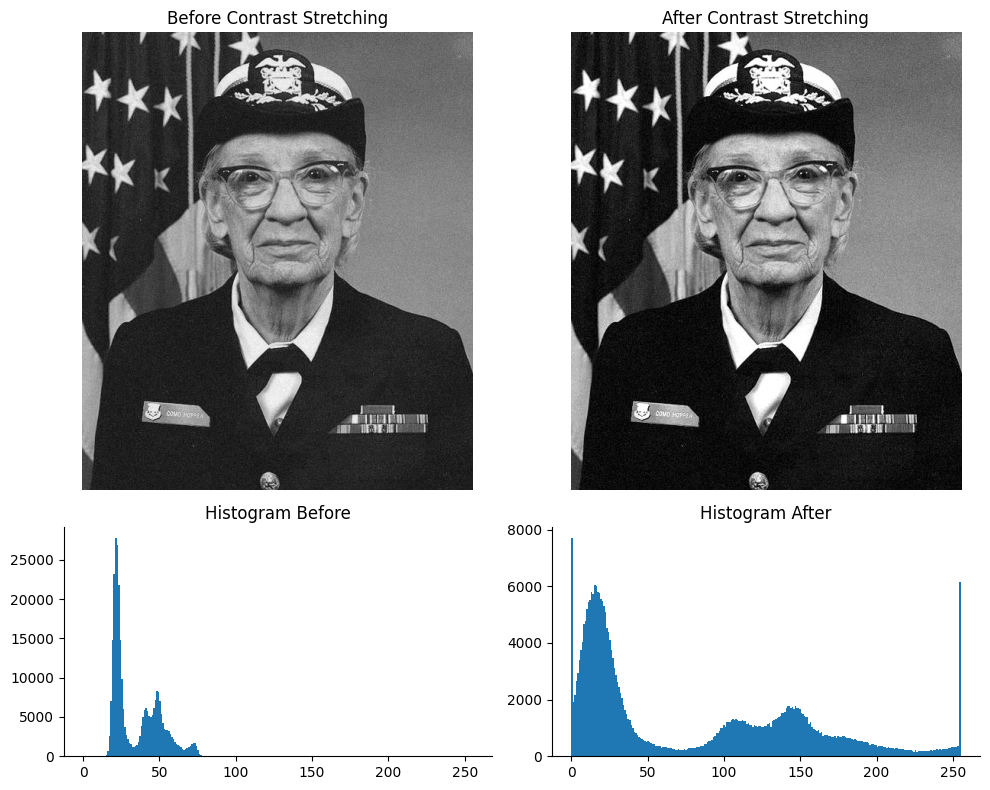

Contrast before: 0.591  ->  after: 1.000


In [10]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p2, p98 = np.percentile(night_still, (2, 98))
c_before = michelson(p98, p2)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip(
    (night_still.astype(float) - p2) / (p98 - p2) * 255,
    0, 255
).astype(np.uint8)

p2_after, p98_after = np.percentile(stretched, (2, 98))
c_after = michelson(p98_after, p2_after)

# TODO 1 & 4: top row = images, bottom row = histograms
fig, axes = plt.subplots(
    2, 2, figsize=(10, 8),
    gridspec_kw={"height_ratios": [2, 1]}
)

axes[0, 0].imshow(night_still, cmap="gray")
axes[0, 0].set_title("Before Contrast Stretching")
axes[0, 0].axis("off")

axes[0, 1].imshow(stretched, cmap="gray")
axes[0, 1].set_title("After Contrast Stretching")
axes[0, 1].axis("off")

axes[1, 0].hist(night_still.ravel(), bins=256, range=(0, 255))
axes[1, 0].set_title("Histogram Before")

axes[1, 1].hist(stretched.ravel(), bins=256, range=(0, 255))
axes[1, 1].set_title("Histogram After")

plt.tight_layout()
plt.show()

print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_

The night image has a narrow, low-contrast histogram concentrated toward the darker intensity values. Stretching spreads the pixel intensities across a wider range, making details easier to distinguish without adding new information. A histogram only shows intensity distribution, not pixel locations, so different images can have the same histogram.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).


Standing time ranges:
68.70s - 68.70s
68.77s - 68.77s
68.87s - 70.53s
70.60s - 70.83s
70.90s - 71.13s
71.20s - 71.63s
71.70s - 72.03s
72.10s - 72.13s
72.23s - 72.73s
72.80s - 73.23s
73.30s - 73.73s
73.80s - 73.90s
73.97s - 74.03s
74.10s - 74.23s
74.30s - 74.67s
74.73s - 75.37s
75.43s - 75.47s
75.53s - 75.57s
75.63s - 75.67s
75.73s - 75.73s
75.80s - 75.90s
75.97s - 76.53s
76.63s - 76.93s
77.00s - 78.10s

Running time ranges:
78.60s - 86.00s

Event frames:
Audio event: 2250
Lighting event: 3000


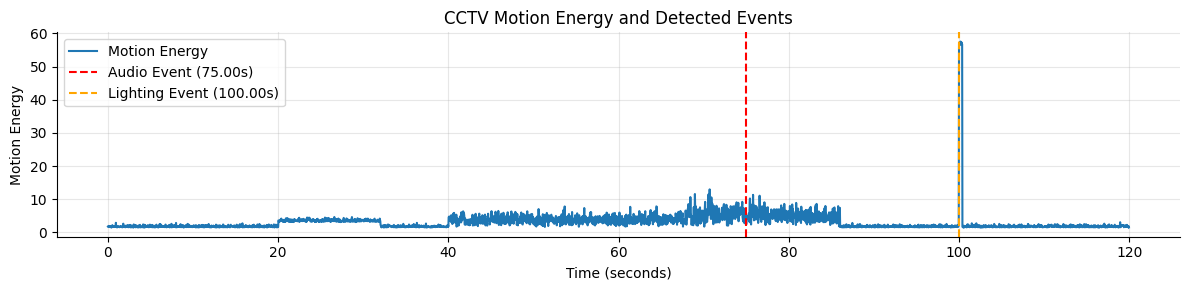

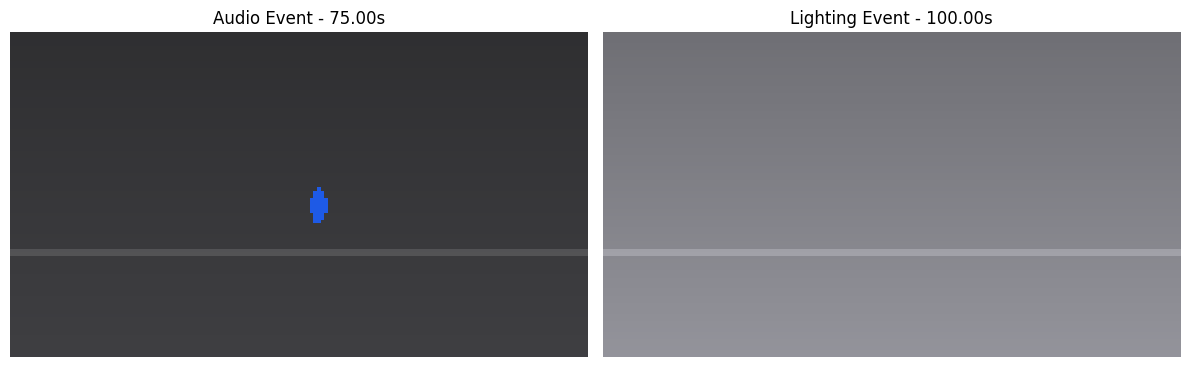

In [11]:
# TODO 1: person speed (px/s)
dx = cctv["person_x"].diff(FPS)
dy = cctv["person_y"].diff(FPS)

speed = np.sqrt(dx**2 + dy**2)

time = np.arange(len(cctv)) / FPS

# TODO 2: standing / running time ranges

def print_ranges(mask, label):
    groups = (mask != mask.shift()).cumsum()

    print(f"\n{label} time ranges:")
    for _, group in mask[mask].groupby(groups[mask]):
        start = group.index[0] / FPS
        end = group.index[-1] / FPS
        print(f"{start:.2f}s - {end:.2f}s")

standing = (speed < 3).fillna(False)
running = (speed > 25).fillna(False)

print_ranges(standing, "Standing")
print_ranges(running, "Running")

# TODO 3: event frame indices

audio_events = np.where(cctv["audio_level_db"].to_numpy() > -20)[0]
audio_event_idx = audio_events[0] if len(audio_events) else None

brightness_change = cctv["mean_brightness"].diff().abs()
lighting_events = np.where(brightness_change.to_numpy() > 40)[0]
lighting_event_idx = lighting_events[0] if len(lighting_events) else None

print("\nEvent frames:")
print("Audio event:", audio_event_idx)
print("Lighting event:", lighting_event_idx)

# TODO 4: annotated motion-energy timeline

fig, ax = plt.subplots(figsize=(12, 3))

ax.plot(time, cctv["motion_energy"], label="Motion Energy")

if audio_event_idx is not None:
    audio_time = audio_event_idx / FPS
    ax.axvline(audio_time, color="red", linestyle="--",
               label=f"Audio Event ({audio_time:.2f}s)")

if lighting_event_idx is not None:
    lighting_time = lighting_event_idx / FPS
    ax.axvline(lighting_time, color="orange", linestyle="--",
               label=f"Lighting Event ({lighting_time:.2f}s)")

ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Motion Energy")
ax.set_title("CCTV Motion Energy and Detected Events")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# TODO 5: one keyframe per event

event_frames = []

if audio_event_idx is not None:
    event_frames.append(("Audio Event", audio_event_idx))

if lighting_event_idx is not None:
    event_frames.append(("Lighting Event", lighting_event_idx))

fig, axes = plt.subplots(
    1, len(event_frames),
    figsize=(6 * len(event_frames), 4),
    squeeze=False
)

for ax, (label, idx) in zip(axes[0], event_frames):
    ax.imshow(render_frame(cctv.iloc[idx]))
    ax.set_title(f"{label} - {idx/FPS:.2f}s")
    ax.axis("off")

plt.tight_layout()
plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_

Uniform keyframes could miss the brief audio and lighting events because they may occur between the 20-second intervals. The approach used instead is content-based keyframe extraction, which selects frames based on significant events or changes in activity.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

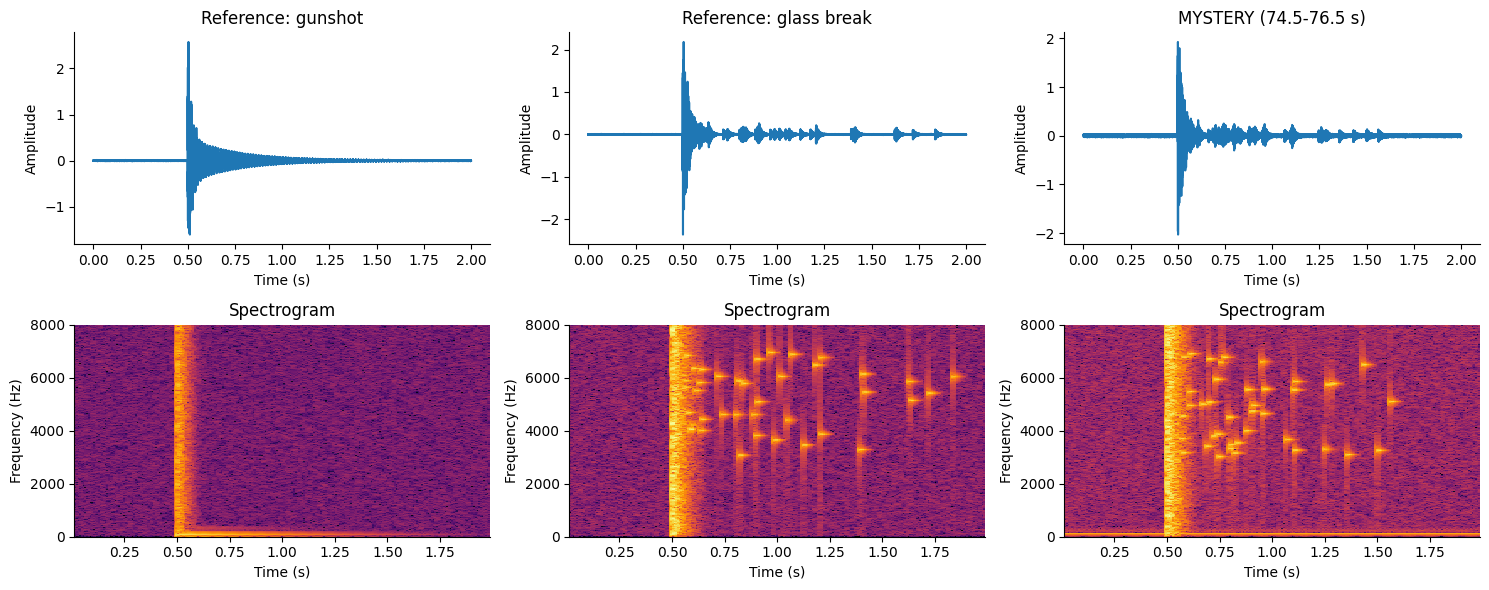

High-frequency energy fractions:
{'Reference: gunshot': np.float64(0.0030352610136762824), 'Reference: glass break': np.float64(0.9891874044148661), 'MYSTERY (74.5-76.5 s)': np.float64(0.8734552491106997)}
Verdict: The mystery sound is most likely BREAKING GLASS.


In [12]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {
    "Reference: gunshot": ref_gunshot[1],
    "Reference: glass break": ref_glass[1],
    "MYSTERY (74.5-76.5 s)": mystery
}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))

# TODO 1 & 2: waveform and spectrogram
for i, (name, x) in enumerate(clips.items()):
    t = np.arange(len(x)) / FS

    # Waveform
    axes[0, i].plot(t, x)
    axes[0, i].set_title(name)
    axes[0, i].set_xlabel("Time (s)")
    axes[0, i].set_ylabel("Amplitude")

    # Spectrogram
    f, ts, Sxx = signal.spectrogram(
        x, fs=FS, nperseg=512, noverlap=384
    )

    Sxx_db = 10 * np.log10(Sxx + 1e-12)

    axes[1, i].pcolormesh(
        ts, f, Sxx_db, shading="auto", cmap="inferno"
    )
    axes[1, i].set_ylim(0, 8000)
    axes[1, i].set_title("Spectrogram")
    axes[1, i].set_xlabel("Time (s)")
    axes[1, i].set_ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()

# TODO 3: fraction of energy above 3 kHz
hf_fraction = {}

for name, x in clips.items():
    f, ts, Sxx = signal.spectrogram(
        x, fs=FS, nperseg=512, noverlap=384
    )

    # 0.2–1.2 seconds after impact
    time_mask = (ts >= 0.7) & (ts <= 1.7)
    freq_mask = f > 3000

    total_energy = Sxx[:, time_mask].sum()
    high_energy = Sxx[freq_mask][:, time_mask].sum()

    hf_fraction[name] = high_energy / total_energy

print("High-frequency energy fractions:")
print(hf_fraction)

# TODO 4: verdict
gunshot_fraction = hf_fraction["Reference: gunshot"]
glass_fraction = hf_fraction["Reference: glass break"]
mystery_fraction = hf_fraction["MYSTERY (74.5-76.5 s)"]

if abs(mystery_fraction - glass_fraction) < abs(mystery_fraction - gunshot_fraction):
    print("Verdict: The mystery sound is most likely BREAKING GLASS.")
else:
    print("Verdict: The mystery sound is most likely a GUNSHOT.")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_

No, the waveforms alone would not let me confidently distinguish them because both show a sharp transient followed by a decay. The spectrogram adds three dimensions: time, frequency, and signal intensity (energy), with intensity represented by colour. The scattered high-frequency specks decided the verdict: they indicate the lingering glass-like tinkles, so the mystery sound is most likely breaking glass.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

/tmp/ipykernel_5735/1180135423.py:82: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


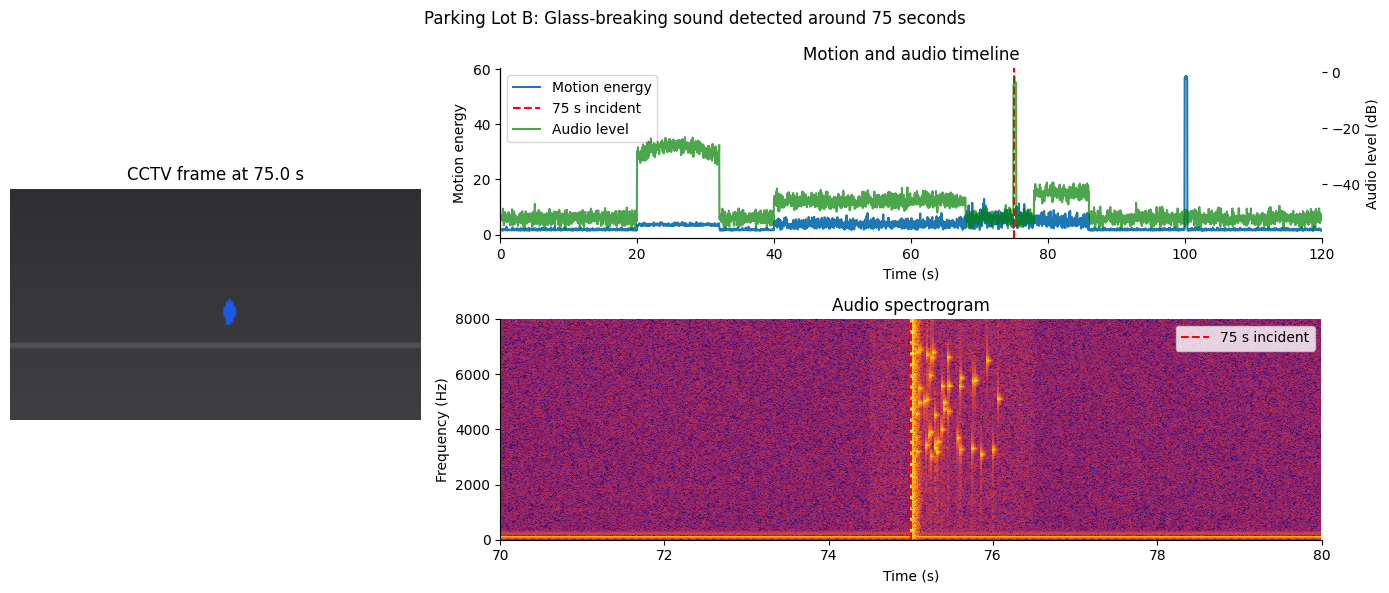

In [13]:
t_sel = 75.0

fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(
    2, 2,
    width_ratios=[1, 2],
    height_ratios=[1, 1.3]
)

# TODO 1: CCTV frame at 75 seconds
frame_idx = int(round(t_sel * FPS))
frame_idx = min(frame_idx, len(cctv) - 1)

ax_frame = fig.add_subplot(gs[:, 0])
ax_frame.imshow(render_frame(cctv.iloc[frame_idx]))
ax_frame.set_title(f"CCTV frame at {t_sel:.1f} s")
ax_frame.axis("off")

# TODO 2: Motion and audio timeline
ax_timeline = fig.add_subplot(gs[0, 1])

video_time = np.arange(len(cctv)) / FPS

ax_timeline.plot(
    video_time, cctv["motion_energy"],
    label="Motion energy"
)
ax_timeline.set_xlim(0, 120)
ax_timeline.set_xlabel("Time (s)")
ax_timeline.set_ylabel("Motion energy")

ax_audio = ax_timeline.twinx()
ax_audio.plot(
    video_time, cctv["audio_level_db"],
    color="green", alpha=0.7,
    label="Audio level"
)
ax_audio.set_ylabel("Audio level (dB)")

ax_timeline.axvline(
    t_sel, color="red", linestyle="--",
    label="75 s incident"
)
ax_timeline.set_title("Motion and audio timeline")

lines1, labels1 = ax_timeline.get_legend_handles_labels()
lines2, labels2 = ax_audio.get_legend_handles_labels()
ax_timeline.legend(lines1 + lines2, labels1 + labels2)

# TODO 3: Audio spectrogram
ax_spec = fig.add_subplot(gs[1, 1])

freqs, spec_times, Sxx = signal.spectrogram(
    x_audio, fs=FS,
    nperseg=512, noverlap=384
)

Sxx_db = 10 * np.log10(Sxx + 1e-12)

ax_spec.pcolormesh(
    spec_times + 70, freqs, Sxx_db,
    shading="auto", cmap="inferno"
)

ax_spec.set_ylim(0, 8000)
ax_spec.set_xlim(70, 80)
ax_spec.set_xlabel("Time (s)")
ax_spec.set_ylabel("Frequency (Hz)")
ax_spec.set_title("Audio spectrogram")

ax_spec.axvline(
    t_sel, color="red", linestyle="--",
    label="75 s incident"
)
ax_spec.legend()

# TODO 4: Conclusion title
fig.suptitle(
    "Parking Lot B: Glass-breaking sound detected around 75 seconds"
)

plt.tight_layout()
plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_

A +2 s offset would make the sound appear to happen two seconds after the actual video event, causing the team to associate it with the wrong action or person. The spectrogram panel would reveal the mismatch because its event marker would not align with the corresponding moment on the motion and audio timeline.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_

The analysis identifies a glass-breaking sound in Parking Lot B between approximately 74.5 and 76.5 seconds, although the exact visual action and person involved should be confirmed from the CCTV keyframes. I would put the synchronized view first because it combines the video, motion and audio at the same timestamp, following the lecture concept of connecting structure, patterns and changes to identify an event. For routine storage, I recommend downsampling to 640 × 360 at 10 fps, which reduces the estimated daily storage for 400 cameras from about 5,866 TB to 217 TB. However, the system must preserve full-resolution footage around detected incidents so that important identifying details, such as faces and number plates, are not permanently lost.